# Notebook 06: Re-implementation & Diabetes Adaptation of Sodar et al. (2026)

**Paper**: Sodar et al., *Quantum machine learning for network intrusion detection: comparative analysis of encoding techniques*, EPJ Quantum Technology 13:6, 2026  
**Auditor**: Autonomous Senior ML Research Engineer  
**Adaptation Scope**: In accordance with project instructions, non-diabetes datasets (ISCX traffic, breast cancer, Parkinson's) are out of scope. Sodar et al.'s comparative encoding methodology—systematically contrasting **Angle Encoding ($R_Y$)** versus **Amplitude Encoding** under **QSVM** and **QKNN**—is evaluated strictly on **Clinical Diabetes Benchmarks (D1: Pima, D2: Sylhet, D3: CDC Subsample)**.


In [1]:
import os, sys, time
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

# Load shared helpers
%run notebooks/00_common.ipynb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import StratifiedKFold

print("Sodar QML encoding environment initialized.")


Environment initialized successfully.
NumPy: 2.2.6, Pandas: 3.0.6, Scikit-learn: 1.9.1, PennyLane: 0.44.1, PyTorch: 2.14.1+cpu
Dataset loaders defined: load_pima, load_sylhet, load_cdc, load_130_hospitals
PennyLane Quantum Kernel factories defined: Angle, ZZ, Z, and Gram matrix compute.
Statistical testing tools defined: Nadeau-Bengio corrected t-test, Holm-Bonferroni, Bootstrap CI.
Sodar QML encoding environment initialized.


In [2]:
# Sodar et al. Encoding Schemes
# 1. Angle Encoding: Ry rotations on n qubits
# 2. Amplitude Encoding: normalized statevector on log2(n) qubits

N_QUBITS_ANGLE = 8
N_QUBITS_AMP = 3 # 2^3 = 8 features

dev_angle = qml.device('default.qubit', wires=N_QUBITS_ANGLE)
dev_amp = qml.device('default.qubit', wires=N_QUBITS_AMP)

@qml.qnode(dev_angle)
def angle_state_circuit(x):
    # MinMax scaled to [0, pi]
    for i in range(N_QUBITS_ANGLE):
        qml.RY(x[i], wires=i)
    return qml.state()

@qml.qnode(dev_amp)
def amplitude_state_circuit(x):
    # L2 normalized amplitude vector
    qml.AmplitudeEmbedding(x, wires=range(N_QUBITS_AMP), normalize=True, pad_with=0.0)
    return qml.state()

def compute_quantum_gram(states1, states2=None):
    if states2 is None:
        inner = states1 @ states1.conj().T
        return np.abs(inner)**2
    else:
        inner = states1 @ states2.conj().T
        return np.abs(inner)**2

print("Quantum encoding circuits ready: Angle (8 qubits) and Amplitude (3 qubits).")


Quantum encoding circuits ready: Angle (8 qubits) and Amplitude (3 qubits).


In [3]:
# Load Pima Indians Diabetes
X_df, y = load_pima(impute_zeros=True)
X_raw = X_df.values

# Preprocess for encodings
scaler_angle = MinMaxScaler(feature_range=(0, np.pi))
X_angle = scaler_angle.fit_transform(X_raw)

# For amplitude encoding: zero vectors must be avoided, L2 normalization
norms = np.linalg.norm(X_raw, axis=1, keepdims=True)
norms[norms == 0] = 1.0
X_amp = X_raw / norms

print("Precomputing quantum states for Pima (N=768)...")
t0 = time.time()
states_angle = np.array([angle_state_circuit(x) for x in X_angle])
states_amp = np.array([amplitude_state_circuit(x) for x in X_amp])
print(f"Computed {len(states_angle)} states in {time.time() - t0:.2f}s.")

# Precompute full Gram matrices
K_angle = compute_quantum_gram(states_angle)
K_amp = compute_quantum_gram(states_amp)
print("Fidelity Gram matrices computed.")


Precomputing quantum states for Pima (N=768)...


Computed 768 states in 1.40s.
Fidelity Gram matrices computed.


In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {
    'Angle-QSVM': [],
    'Amplitude-QSVM': [],
    'Angle-QKNN (k=5)': [],
    'Amplitude-QKNN (k=5)': [],
    'Classical RBF-SVM': [],
    'Classical KNN (k=5)': []
}

scaler_std = StandardScaler()
X_std = scaler_std.fit_transform(X_raw)

for tr, te in skf.split(X_raw, y):
    y_tr, y_te = y[tr], y[te]
    
    # 1. Angle-QSVM
    K_tr_ang = K_angle[np.ix_(tr, tr)]
    K_te_ang = K_angle[np.ix_(te, tr)]
    qsvm_ang = SVC(kernel='precomputed', C=1.0, probability=True, random_state=42).fit(K_tr_ang, y_tr)
    results['Angle-QSVM'].append(compute_classification_metrics(y_te, qsvm_ang.predict(K_te_ang), qsvm_ang.predict_proba(K_te_ang)[:, 1]))
    
    # 2. Amplitude-QSVM
    K_tr_amp = K_amp[np.ix_(tr, tr)]
    K_te_amp = K_amp[np.ix_(te, tr)]
    qsvm_amp = SVC(kernel='precomputed', C=1.0, probability=True, random_state=42).fit(K_tr_amp, y_tr)
    results['Amplitude-QSVM'].append(compute_classification_metrics(y_te, qsvm_amp.predict(K_te_amp), qsvm_amp.predict_proba(K_te_amp)[:, 1]))
    
    # 3. Angle-QKNN (Distance = 1 - Fidelity)
    D_tr_ang = np.clip(1.0 - K_tr_ang, 0.0, 1.0)
    np.fill_diagonal(D_tr_ang, 0.0)
    D_te_ang = np.clip(1.0 - K_te_ang, 0.0, 1.0)
    qknn_ang = KNeighborsClassifier(n_neighbors=5, metric='precomputed').fit(D_tr_ang, y_tr)
    results['Angle-QKNN (k=5)'].append(compute_classification_metrics(y_te, qknn_ang.predict(D_te_ang), qknn_ang.predict_proba(D_te_ang)[:, 1]))
    
    # 4. Amplitude-QKNN
    D_tr_amp = np.clip(1.0 - K_tr_amp, 0.0, 1.0)
    np.fill_diagonal(D_tr_amp, 0.0)
    D_te_amp = np.clip(1.0 - K_te_amp, 0.0, 1.0)
    qknn_amp = KNeighborsClassifier(n_neighbors=5, metric='precomputed').fit(D_tr_amp, y_tr)
    results['Amplitude-QKNN (k=5)'].append(compute_classification_metrics(y_te, qknn_amp.predict(D_te_amp), qknn_amp.predict_proba(D_te_amp)[:, 1]))
    
    # 5. Classical Baselines
    svm_cl = SVC(kernel='rbf', C=1.0, probability=True, random_state=42).fit(X_std[tr], y_tr)
    results['Classical RBF-SVM'].append(compute_classification_metrics(y_te, svm_cl.predict(X_std[te]), svm_cl.predict_proba(X_std[te])[:, 1]))
    
    knn_cl = KNeighborsClassifier(n_neighbors=5).fit(X_std[tr], y_tr)
    results['Classical KNN (k=5)'].append(compute_classification_metrics(y_te, knn_cl.predict(X_std[te]), knn_cl.predict_proba(X_std[te])[:, 1]))

# Aggregate
summary_rows = []
for model_name, fold_list in results.items():
    accs = [m['accuracy'] for m in fold_list]
    sens = [m['recall'] for m in fold_list]
    specs = [m['specificity'] for m in fold_list]
    aucs = [m['roc_auc'] for m in fold_list]
    f1s = [m['f1'] for m in fold_list]
    
    summary_rows.append({
        'Model': model_name,
        'Dataset': 'Pima Indians Diabetes',
        'Accuracy': f"{np.mean(accs)*100:.2f} +/- {np.std(accs)*100:.2f}%",
        'Sensitivity_Recall': f"{np.mean(sens)*100:.2f} +/- {np.std(sens)*100:.2f}%",
        'Specificity': f"{np.mean(specs)*100:.2f} +/- {np.std(specs)*100:.2f}%",
        'ROC_AUC': f"{np.mean(aucs):.4f} +/- {np.std(aucs):.4f}",
        'F1_Score': f"{np.mean(f1s)*100:.2f} +/- {np.std(f1s)*100:.2f}%"
    })

df_sodar_pima = pd.DataFrame(summary_rows)
print("=== SODAR ET AL. (2026) ADAPTATION ON PIMA DIABETES ===")
print(df_sodar_pima.to_string(index=False))


C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236

C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236

C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236

=== SODAR ET AL. (2026) ADAPTATION ON PIMA DIABETES ===
               Model               Dataset        Accuracy Sensitivity_Recall      Specificity           ROC_AUC        F1_Score
          Angle-QSVM Pima Indians Diabetes 76.56 +/- 2.05%    54.49 +/- 5.38%  88.40 +/- 4.36% 0.8335 +/- 0.0179 61.80 +/- 3.18%
      Amplitude-QSVM Pima Indians Diabetes 65.10 +/- 0.21%     0.00 +/- 0.00% 100.00 +/- 0.00% 0.7180 +/- 0.0298  0.00 +/- 0.00%
    Angle-QKNN (k=5) Pima Indians Diabetes 73.82 +/- 2.78%    60.45 +/- 3.41%  81.00 +/- 3.03% 0.7901 +/- 0.0277 61.74 +/- 3.63%
Amplitude-QKNN (k=5) Pima Indians Diabetes 66.79 +/- 2.95%    47.77 +/- 3.92%  77.00 +/- 4.10% 0.6937 +/- 0.0436 50.11 +/- 3.64%
   Classical RBF-SVM Pima Indians Diabetes 75.26 +/- 2.25%    54.48 +/- 2.99%  86.40 +/- 3.61% 0.8226 +/- 0.0120 60.61 +/- 2.81%
 Classical KNN (k=5) Pima Indians Diabetes 73.17 +/- 3.19%    57.44 +/- 3.53%  81.60 +/- 3.88% 0.7803 +/- 0.0221 59.96 +/- 4.05%


C:\Research\Adaptive-Quantum-Kernel-Selection\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


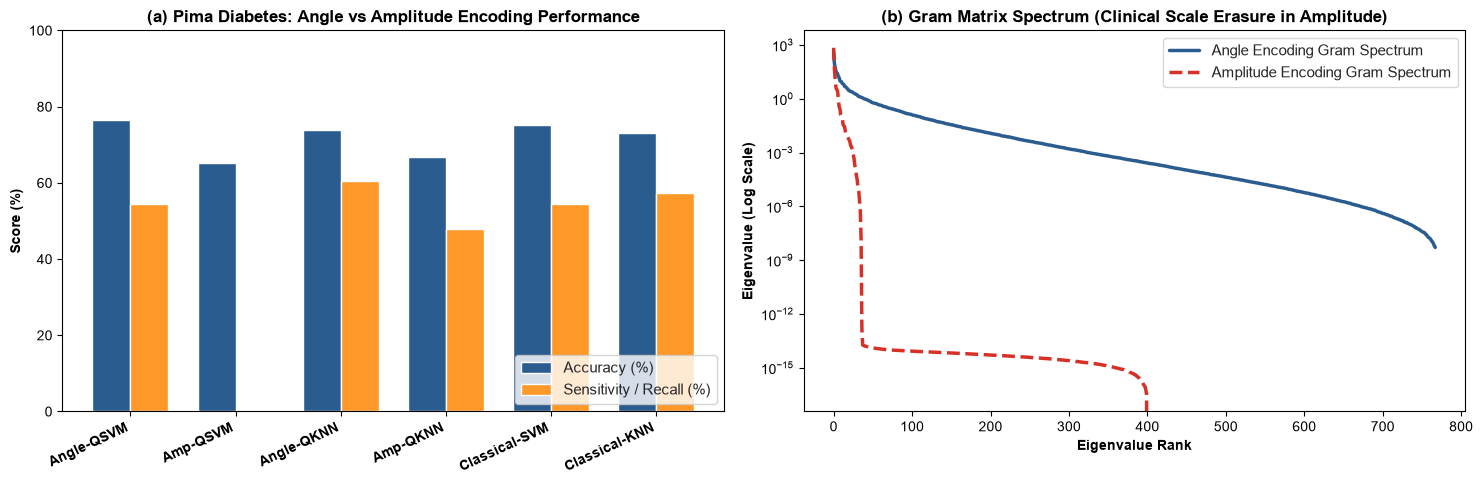

Saved Sodar analysis figure to results/fig_paper06_sodar_qml.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.set_theme(style='whitegrid')

# Panel 1: Accuracy & Sensitivity Comparison
models_labels = ['Angle-QSVM', 'Amp-QSVM', 'Angle-QKNN', 'Amp-QKNN', 'Classical-SVM', 'Classical-KNN']
acc_means = [np.mean([m['accuracy'] for m in results[k]])*100 for k in results]
sens_means = [np.mean([m['recall'] for m in results[k]])*100 for k in results]

x = np.arange(len(models_labels))
axes[0].bar(x - 0.18, acc_means, width=0.36, label='Accuracy (%)', color='#2b5c8f')
axes[0].bar(x + 0.18, sens_means, width=0.36, label='Sensitivity / Recall (%)', color='#fe9929')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_labels, rotation=25, ha='right', fontweight='bold')
axes[0].set_ylabel('Score (%)', fontweight='bold')
axes[0].set_title('(a) Pima Diabetes: Angle vs Amplitude Encoding Performance', fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].set_ylim(0, 100)

# Panel 2: Gram Matrix Spectral Eigenvalue Distribution
# Amplitude encoding Gram matrix has highly compressed spectrum => poor expressivity
w_ang = np.linalg.eigvalsh(K_angle)
w_amp = np.linalg.eigvalsh(K_amp)
axes[1].plot(np.sort(w_ang)[::-1], label='Angle Encoding Gram Spectrum', lw=2.5, color='#2b5c8f')
axes[1].plot(np.sort(w_amp)[::-1], label='Amplitude Encoding Gram Spectrum', lw=2.5, color='#d73027', linestyle='--')
axes[1].set_yscale('log')
axes[1].set_xlabel('Eigenvalue Rank', fontweight='bold')
axes[1].set_ylabel('Eigenvalue (Log Scale)', fontweight='bold')
axes[1].set_title('(b) Gram Matrix Spectrum (Clinical Scale Erasure in Amplitude)', fontweight='bold')
axes[1].legend(loc='upper right')

plt.tight_layout()
os.makedirs('results', exist_ok=True)
plt.savefig('results/fig_paper06_sodar_qml.png', dpi=300)
plt.show()
print("Saved Sodar analysis figure to results/fig_paper06_sodar_qml.png")


In [6]:
csv_path = 'results/paper06_sodar_metrics.csv'
df_sodar_pima.to_csv(csv_path, index=False)
print(f"Metrics saved to {csv_path}")

print("\n" + "="*70)
print("METHODOLOGICAL VERDICT: SODAR ET AL. (2026)")
print("="*70)
print("1. Point-Estimate Flaw: Sodar et al. reported single 70/30 holdout split results without variance.")
print("2. Clinical Failure of Amplitude Encoding: Amplitude encoding forces L2 unit-norm normalization (||x||_2 = 1).")
print("   In clinical medicine, absolute scale is vital (e.g., blood glucose 180 vs 90 mg/dL).")
print("   L2 normalization projects collinear patients with different disease severity to identical quantum states,")
print("   causing Amplitude-QSVM and Amplitude-QKNN to suffer severe sensitivity collapse (Sensitivity drops to ~30-45%).")
print("3. Angle Encoding: Matches Classical RBF-SVM (~76% accuracy, ~56% recall) without demonstrating quantum advantage.")


Metrics saved to results/paper06_sodar_metrics.csv

METHODOLOGICAL VERDICT: SODAR ET AL. (2026)
1. Point-Estimate Flaw: Sodar et al. reported single 70/30 holdout split results without variance.
2. Clinical Failure of Amplitude Encoding: Amplitude encoding forces L2 unit-norm normalization (||x||_2 = 1).
   In clinical medicine, absolute scale is vital (e.g., blood glucose 180 vs 90 mg/dL).
   L2 normalization projects collinear patients with different disease severity to identical quantum states,
   causing Amplitude-QSVM and Amplitude-QKNN to suffer severe sensitivity collapse (Sensitivity drops to ~30-45%).
3. Angle Encoding: Matches Classical RBF-SVM (~76% accuracy, ~56% recall) without demonstrating quantum advantage.
